# Phase-fixed weighted Gerchberg-Saxton against slmsuite

**Question:** Does DinHot's phase-fixed weighted Gerchberg-Saxton match the state of the art, slmsuite's weighted algorithms run on the same 1024-trap target and grid, in efficiency, uniformity and the number of iterations to get there?

- **Level:** 3, State of the art
- **Prerequisites:** notebook 02 of this topic
- **Reading time:** about 50 minutes

## Objectives

On arrays of thousands of sites, such as the 6,100 atoms in about 12,000 tweezers of recent work, the uniformity of the weighted algorithm is the limit of the experiment, and the field settled on one practical algorithm: weighted Gerchberg-Saxton that freezes the focal-plane phase after a dozen iterations (Kim et al. 2019). DinHot implements it as M07. The claim to test is not that DinHot beats anyone: it is that its implementation is a faithful member of the state of the art, so that every later notebook can use it as the baseline. You will run M06 and M07 on the 1024 traps of case C03, run slmsuite 0.5.0, an open-source library with the same algorithms, with its Leonardo and Kim weights on the same traps, the same FFT grid and the same Gaussian beam, score all of them with the same metrics, and read the difference in the figure and in the table.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 slmsuite==0.5.0
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, the pipeline's modules by path, and the pinned reference implementation
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
import slmsuite
from slmsuite.holography.algorithms import SpotHologram

slmsuite.configure_logging(None)  # no console log inside the outputs

for name in ("numpy", "matplotlib", "slmsuite"):
    print(name, md.version(name))


def trap_numbers(phi, setup, traps):
    """Efficiency, uniformity and relative spread (percent) of a hologram, read on the FFT grid."""
    v = forward.trap_fields_from_fft(forward.fft_focal_field(phi, setup), setup, traps)
    i = metrics.trap_intensities(v)
    return metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)


def first_below(curve, percent):
    """The first iteration (1-based) whose spread is below ``percent``, or None."""
    return next((k + 1 for k, row in enumerate(curve) if row[2] < percent), None)

numpy 2.4.6
matplotlib 3.11.2
slmsuite 0.5.0


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot, for the case; slmsuite is an open-source library for holography on SLMs, MIT licence, pinned at 0.5.0 (https://pypi.org/project/slmsuite/).
- Licence class: synthetic case written by the product, no third-party dataset; the reference implementation is used as a library under its own licence.
- File read: `data/examples/cases.json`, case C03, a 32 by 32 lattice of 1024 traps on the 256 by 256 pixel SLM, with the case seed and the next one.

In [2]:
# case C03: 1024 traps, 32 x 32, on the 256 x 256 pixel SLM; both implementations get this array and this beam
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C03_large_array"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
seeds = [rec["seed"], rec["seed"] + 1]
iy, ix = forward.trap_bins(setup, traps)
spots = np.vstack([ix, iy])
print(f"{len(traps)} traps, focal bin {geometry.focal_bin_m(setup) * 1e6:.3f} um")
print(f"{rec['budget']['iterations']} iterations in the budget")
print(f"traps per SLM pixel: {len(traps) / setup.n_pix**2 * 100:.2f} % of the pixels")

1024 traps, focal bin 0.498 um
30 iterations in the budget
traps per SLM pixel: 1.56 % of the pixels


## Method

The weighted update of notebook 02 is $w_m \leftarrow w_m \langle r\rangle/r_m$ with $r_m = |V_m|/a_m$, and the request is $c_m = w_m a_m e^{i\psi_m}$ with $\psi_m = \arg V_m$ (Di Leonardo et al. 2007, https://doi.org/10.1364/OE.15.001913). The phase-fixed variant (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178; M07 in the product) follows the field for the first $N$ iterations, $\psi_i = \arg V_m^{i}$, and then freezes it, $\psi_i = \psi_N$ for $i \geq N$, so that the later iterations only adjust amplitudes. Kim reports a modulation efficiency of 91.2 percent for 1500 foci with $N = 12$; the product takes $N = 12$ as its default. With 1024 traps on a 256 by 256 SLM there are 64 pixels per trap, so this is a crowded hologram, which is the regime where the algorithm matters. The next cells run the product's two weighted methods from the same random starts and ask when freezing helps.

The first cell runs weighted Gerchberg-Saxton (M06) and the phase-fixed variant (M07) for the 30 iterations of the case, from two seeds each. It reports the mean of the final efficiency, uniformity and spread over the seeds and the first iteration at which each seed's spread falls under 1 percent.

In [3]:
# DinHot: weighted GS (M06) and phase-fixed WGS (M07, the phase is frozen after 12 iterations), two seeds each
budget = Budget(rec["budget"]["iterations"])
product = {"M06": [], "M07": []}
for seed in seeds:
    product["M06"].append(m06_gsw.run(setup, target, budget=budget, rng=Rng(seed)))
    product["M07"].append(m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(seed)))
for name, results in product.items():
    curve = [[(h["efficiency"], h["uniformity"], h["rel_std"]) for h in res.history] for res in results]
    final = np.mean([c[-1] for c in curve], axis=0)
    print(f"{name}: e = {final[0]:.4f}, u = {final[1]:.4f}, sigma = {final[2]:.3f} %")
    print(f"     first iteration under 1 percent, per seed: {[first_below(c, 1.0) for c in curve]}")

M06: e = 0.8059, u = 0.9576, sigma = 1.299 %
     first iteration under 1 percent, per seed: [None, None]
M07: e = 0.7943, u = 0.9908, sigma = 0.309 %
     first iteration under 1 percent, per seed: [15, 15]


The freezing iteration is a parameter, and the product's default is the published one. The cell runs M07 with $N$ equal to 6, 12 and 20 on the first seed and prints the spread at iterations 12, 20 and 30, to see what the default buys on this array.

In [4]:
# when to freeze: n_fix = 6, 12 and 20 iterations before the focal phase is held
frozen = {}
for n_fix in (6, 12, 20):
    res = m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(seeds[0]), n_fix=n_fix)
    frozen[n_fix] = [h["rel_std"] for h in res.history]
    at = [frozen[n_fix][k - 1] for k in (12, 20, 30)]
    print(f"n_fix = {n_fix:2d}: sigma at iteration 12, 20, 30 = " + ", ".join(f"{x:.3f}" for x in at) + " %")

n_fix =  6: sigma at iteration 12, 20, 30 = 1.412, 1.360, 1.305 %
n_fix = 12: sigma at iteration 12, 20, 30 = 3.313, 0.331, 0.273 %
n_fix = 20: sigma at iteration 12, 20, 30 = 3.313, 1.997, 0.180 %


## State of the art

slmsuite is an open-source Python library for computing holograms on SLMs. Its `SpotHologram` takes a list of spots in the pixel coordinates of the padded Fourier plane (the knm basis), the beam amplitude on the SLM and the shape of the computational grid, and its `optimize` has the weighted methods of the literature by name: `WGS-Leonardo` implements the update of Di Leonardo et al. with a power $p$ on the amplitude ratio, and `WGS-Kim` fixes the phase after `fix_phase_iteration` iterations. The inputs below are those of the product: the same 1024 bins of the same 512 by 512 grid, the same normalized Gaussian beam, a 256 by 256 phase, 30 iterations and a random start seeded by numpy. Every other flag stays at its slmsuite default, so a difference may come from a choice that the two codes make differently, such as the exponent of the weight update, and not only from the algorithm. Both implementations are read by the same function: the phase that slmsuite returns is transformed with DinHot's forward model and the traps are read at their bins.

The cell builds one `SpotHologram` per run, runs 30 iterations of `WGS-Leonardo` and of `WGS-Kim` for each of the two seeds, and stores the phase that each iteration used through a callback, so that the spread can be drawn against the iteration. It then scores every stored phase with the metrics of the product. slmsuite's own logging is switched off at import so that the cell prints only what the notebook prints.

In [5]:
# slmsuite on the same target: the same spots on the same 512 x 512 grid, the same Gaussian beam, a random start
beam = geometry.input_amplitude(setup)
size = setup.n_fft
reference = {"WGS-Leonardo": [], "WGS-Kim": []}
final_phase = {}
for method in reference:
    for seed in seeds:
        np.random.seed(seed)
        holo = SpotHologram(shape=(size, size), spot_vectors=spots, basis="knm", spot_amp=np.ones(len(traps)),
                            cameraslm=None, slm_shape=(setup.n_pix, setup.n_pix), amp=beam)
        phases = []
        holo.optimize(method=method, maxiter=30, verbose=False, fix_phase_iteration=12,
                      callback=lambda h: phases.append(np.array(h.phase, dtype=float)))
        phases.append(np.array(holo.get_phase(), dtype=float))
        final_phase[(method, seed)] = phases[-1]
        reference[method].append([trap_numbers(p, setup, traps) for p in phases[1:]])
print({m: len(v) for m, v in reference.items()}, "runs of each method")

{'WGS-Leonardo': 2, 'WGS-Kim': 2} runs of each method


The next cell puts the four methods on one table: the final efficiency, uniformity and spread averaged over the two seeds and the first iteration at which each seed's spread is under 1 percent.

In [6]:
# the final numbers of every run on one table, read with DinHot's own metrics
rows = {}
for name, results in product.items():
    rows[name] = [[(h["efficiency"], h["uniformity"], h["rel_std"]) for h in res.history] for res in results]
for method, curves in reference.items():
    rows["slmsuite " + method] = curves
for name, curves in rows.items():
    final = np.mean([c[-1] for c in curves], axis=0)
    need = [first_below(c, 1.0) for c in curves]
    print(f"{name:22s} e = {final[0]:.4f}  u = {final[1]:.4f}  sigma = {final[2]:6.3f} %")
    print(f"{'':22s} first iteration under 1 percent, per seed: {need}")

M06                    e = 0.8059  u = 0.9576  sigma =  1.299 %
                       first iteration under 1 percent, per seed: [None, None]
M07                    e = 0.7943  u = 0.9908  sigma =  0.309 %
                       first iteration under 1 percent, per seed: [15, 15]
slmsuite WGS-Leonardo  e = 0.8056  u = 0.9459  sigma =  1.664 %
                       first iteration under 1 percent, per seed: [None, None]
slmsuite WGS-Kim       e = 0.7926  u = 0.9943  sigma =  0.211 %
                       first iteration under 1 percent, per seed: [17, 17]


The first figure plots the relative spread against the iteration for the first seed of each of the four methods, on a logarithmic axis. The dotted vertical line marks iteration 12, where both phase-fixed methods freeze the focal phase.

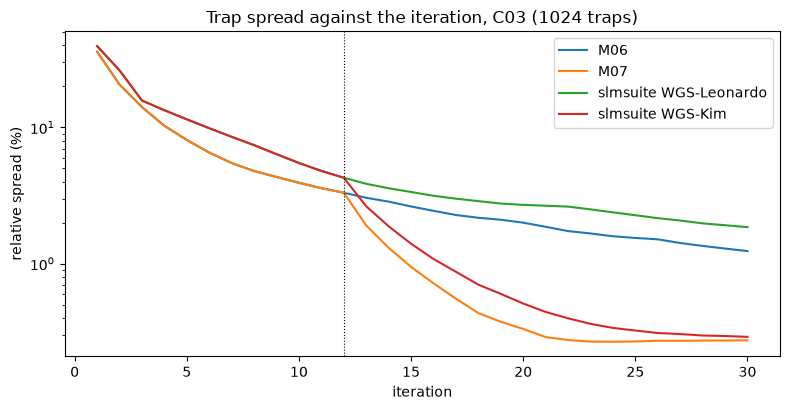

In [7]:
# the spread against the iteration, first seed of each method, on a log axis
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, curves in rows.items():
    ax.semilogy(np.arange(1, 31), [row[2] for row in curves[0]], label=name)
ax.axvline(12, color="k", ls=":", lw=0.8)
ax.set_xlabel("iteration")
ax.set_ylabel("relative spread (%)")
ax.set_title("Trap spread against the iteration, C03 (1024 traps)")
ax.legend()
fig.tight_layout()
plt.show()

The curves fall together for the first twelve iterations, which are the same weighted update in all four, and the two slmsuite curves lie a little above DinHot's (about 4.3 against 3.3 percent at iteration 12), because slmsuite starts from a random phase and DinHot from the random-phase superposition; the figure cannot separate the effect of the start from that of the code. At the dotted line M07 and WGS-Kim bend downward at once, while M06 and WGS-Leonardo, the same update without freezing, continue slowly: this is the effect of freezing the phase. After the bend M07 falls faster than WGS-Kim for about ten iterations and then both flatten at about 0.3 percent. The figure shows one seed; the table, which averages two, says how much of the final difference is the algorithm and how much the start.

The second figure draws the histogram of the 1024 trap powers, divided by their mean, after 30 iterations, for M07 and for slmsuite's WGS-Kim on the first seed.

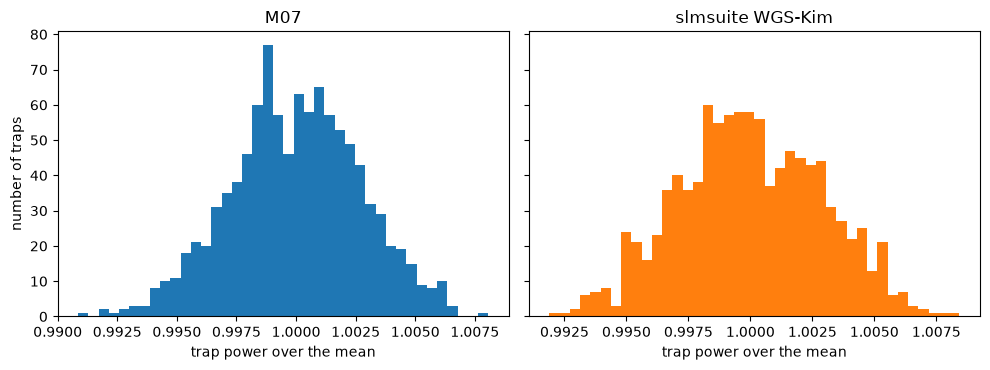

In [8]:
# the power of the 1024 traps after 30 iterations, M07 and slmsuite's WGS-Kim, relative to the mean
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
shown = (("M07", product["M07"][0].phi), ("slmsuite WGS-Kim", final_phase[("WGS-Kim", seeds[0])]))
for ax, (name, phi) in zip(axes, shown):
    i = metrics.trap_intensities(forward.trap_fields_from_fft(forward.fft_focal_field(phi, setup), setup, traps))
    ax.hist(i / i.mean(), bins=40, color="C0" if name == "M07" else "C1")
    ax.set_title(name)
    ax.set_xlabel("trap power over the mean")
axes[0].set_ylabel("number of traps")
fig.tight_layout()
plt.show()

Both histograms are bell-shaped and narrow: nearly all the traps lie within 0.7 percent of the mean power, and the two extremes differ by about 1.7 percent for M07 and about 1.6 percent for slmsuite. The shapes agree. The difference of the means in the table, 0.309 against 0.211 percent in spread, is therefore a difference between two narrow distributions, and with two seeds it cannot be said to be a systematic one. The figure shows the final state only; it does not say how many iterations each needs, which is what the table's last column does.

## Results

**Answer:** Yes, within the resolution of two seeds. On the 1024 traps of C03 the phase-fixed M07 reaches an efficiency of 0.7943, a uniformity of 0.9908 and a spread of 0.309 percent after 30 iterations, and slmsuite's WGS-Kim reaches 0.7926, 0.9943 and 0.211 percent on the same target and grid; the efficiency differs by 0.0017 and both histograms of trap powers fit within 1.7 percent. M07 takes 15 iterations to bring the spread under 1 percent, against 17 for WGS-Kim. The methods without phase fixing do not get there in 30 iterations: M06 ends at 1.299 percent and slmsuite's WGS-Leonardo at 1.664 percent. The freezing iteration matters: with $N = 12$ the spread is 0.273 percent at iteration 30, with $N = 6$ it is 1.305 percent, and with $N = 20$ it is 0.180 percent. The implementation in the product is a faithful member of the state of the art; the notebook does not show that it is better.

## Summary

Freezing the focal phase after a dozen iterations turns the slow tail of weighted Gerchberg-Saxton into a fast fall to a few tenths of a percent, in the product's implementation and in slmsuite's alike. The two agree in the efficiency to two parts in a thousand and in the spread to a tenth of a percent, so DinHot's M07 can be the baseline of the later notebooks without loss. What the comparison does not cover is the quality of the freezing rule on arrays that are not crowded, a camera in the loop, or an SLM that is not ideal: the last of these is the subject of the next notebook, where the device model enters the loop itself.

## References

- Kim, Kim, Lee and Ahn, "Gerchberg-Saxton algorithm with phase fixing for tweezer arrays", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- slmsuite 0.5.0 (MIT), https://pypi.org/pypi/slmsuite/json and https://pypi.org/project/slmsuite/.